# Notebook 1 — CNN with MNIST / ノートブック1：MNISTでCNNを学ぶ
 
**Time / 所要時間:** ~60–75 min / 約60〜75分  
**Framework:** PyTorch; works in Google Colab / Google Colabで実行可能

### Learning goals / 学習目標
1. Understand image tensors and labels. / 画像テンソルとラベルを理解する。
2. See convolution and max pooling numerically. / 畳み込みと最大プーリングを数値で確認する。
3. Train a CNN on MNIST. / MNISTでCNNを学習する。
4. Inspect feature maps, accuracy, and mistakes. / 特徴マップ・正解率・誤分類を可視化する。

**Run each cell from top to bottom. / セルを上から順番に実行してください。**

**Instructor note / 教員向け:** Training times depend on CPU/GPU; set `EPOCHS = 2` if the class is short. / 実行時間は環境に依存します。時間が足りない場合は `EPOCHS = 2` にしてください。

## 0. Environment / 実行環境
**EN:** Import libraries, fix a random seed, and select a GPU when available. A seed improves repeatability but does not guarantee identical results across all hardware. In Colab, change to a GPU runtime if available.

**日本語:** 必要なライブラリを読み込み、乱数シードを固定し、利用可能ならGPUを使います。シード固定は結果の再現性を高めますが、環境が異なると完全に同じ結果になるとは限りません。Colabでは必要に応じてGPUを有効にしてください。

If imports fail in a local environment / ローカル環境で不足する場合: `pip install torch torchvision matplotlib scikit-learn`

In [18]:
# Imports and reproducibility / ライブラリと再現性
import random, time, copy
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
plt.rcParams["font.family"] = "Hiragino Sans"
plt.rcParams["axes.unicode_minus"] = False

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| Device / 使用デバイス:', DEVICE)
# Google Colab: Runtime > Change runtime type > T4 GPU (optional)

PyTorch: 2.5.1 | Device / 使用デバイス: cpu


## 1. Download and inspect MNIST / MNISTの取得と確認
**EN:** MNIST contains 28×28 grayscale handwritten-digit images. The original dataset has 60,000 training and 10,000 test images. We split the original training portion into **55,000 training + 5,000 validation**, reserving the untouched test data for the final evaluation. A grayscale image has shape `[1, 28, 28]` (channel, height, width). `ToTensor()` converts pixel values to approximately [0,1].

**日本語:** MNISTは28×28画素の手書き数字のグレースケール画像です。元のデータは学習用60,000枚とテスト用10,000枚です。今回は学習用から **55,000枚を学習、5,000枚を検証** に分け、テストデータは最後の評価まで使いません。画像の形状は `[1, 28, 28]`（チャネル・高さ・幅）で、`ToTensor()` により画素値がおおむね0〜1になります。

**Why validation? / 検証用データの役割:** Choose settings without repeatedly looking at the test set. / テストデータを繰り返し見ずに設定を調整するためです。

In [2]:
transform = transforms.ToTensor()
full_train = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_data = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
generator = torch.Generator().manual_seed(SEED)
train_data, val_data = torch.utils.data.random_split(full_train, [55000,5000], generator=generator)
BATCH_SIZE=128
train_loader=DataLoader(train_data,batch_size=BATCH_SIZE,shuffle=True,num_workers=0)
val_loader=DataLoader(val_data,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
test_loader=DataLoader(test_data,batch_size=BATCH_SIZE,shuffle=False,num_workers=0)
print('Train:',len(train_data),'Validation:',len(val_data),'Test:',len(test_data))
image,label=full_train[0]
print('Image shape:',tuple(image.shape),'Pixel range:',(image.min().item(),image.max().item()),'Label:',label)

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting ./data/MNIST/raw/train-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting ./data/MNIST/raw/train-labels-idx1-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting ./data/MNIST/raw/t10k-images-idx3-ubyte.gz to ./data/MNIST/raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%

Extracting ./data/MNIST/raw/t10k-labels-idx1-ubyte.gz to ./data/MNIST/raw

Train: 55000 Validation: 5000 Test: 10000
Image shape: (1, 28, 28) Pixel range: (0.0, 1.0) Label: 5


### Visualize samples / サンプル画像の表示
**EN:** A label is the correct digit for an image. Different writing styles make the task nontrivial. The neural network receives numbers (pixels), not the displayed plot.

**日本語:** ラベルは画像に対応する正解の数字です。同じ数字でも書き方が異なるため分類には学習が必要です。ネットワークが受け取るのは表示画像そのものではなく、画素の数値です。

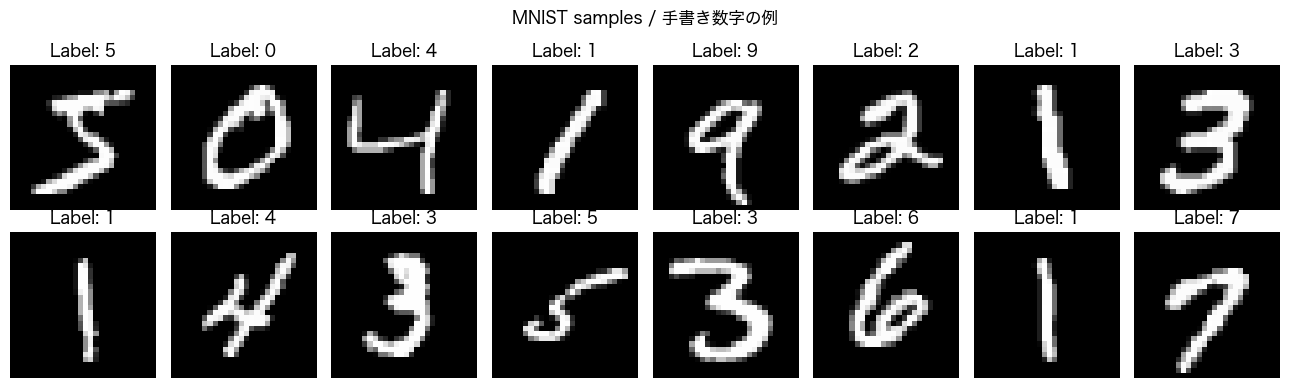

In [19]:
fig,axs=plt.subplots(2,8,figsize=(13,4))
for i,ax in enumerate(axs.flat):
    img,y=full_train[i]
    ax.imshow(img.squeeze(),cmap='gray',vmin=0,vmax=1)
    ax.set_title(f'Label: {y}');ax.axis('off')
plt.suptitle('MNIST samples / 手書き数字の例');plt.tight_layout();plt.show()

## 2. Convolution by hand / 畳み込みを手計算で理解する
**EN:** A small **kernel/filter** slides over an image and computes a weighted sum of neighboring pixel values. A high response can indicate a local pattern such as an edge. Deep-learning libraries often implement *cross-correlation* while calling it convolution; the kernel is not flipped.

For a 3×3 patch and a 3×3 kernel (stride 1, no padding), a 5×5 input produces a 3×3 output: `5 − 3 + 1 = 3`. Each output pixel is computed from 9 multiplications and their sum.

**日本語:** 小さな**カーネル（フィルタ）**を画像上で移動し、近くの画素に重みを掛けて合計します。応答が大きい場所にはエッジなどの局所的な特徴がある可能性があります。深層学習ライブラリで「畳み込み」と呼ぶ演算は、通常カーネルを反転しない**相互相関**です。

5×5の入力に3×3のカーネルをストライド1・パディングなしで適用すると、出力は3×3です。各出力値は9個の積の和で求めます。


$$Y_{i,j} = \sum_{m=0}^{2} \sum_{n=0}^{2} X_{i+m,j+n} K_{m,n}$$

Input / 入力:
 [[0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]
 [0. 0. 1. 1. 1.]]
Kernel / カーネル:
 [[-1.  0.  1.]
 [-1.  0.  1.]
 [-1.  0.  1.]]
First output, manual / 左上を手計算: 3.0
All outputs / 全出力:
 [[3. 3. 0.]
 [3. 3. 0.]
 [3. 3. 0.]]


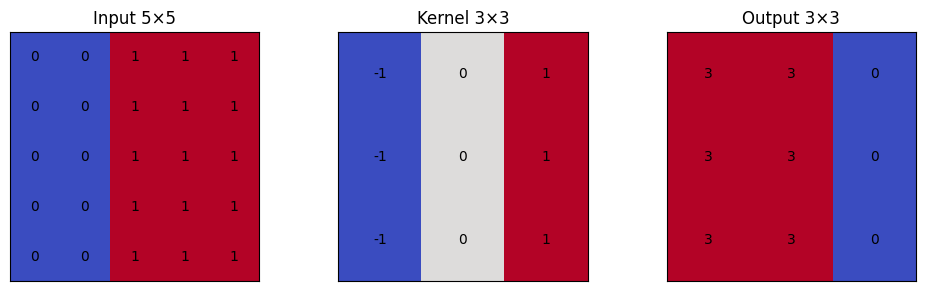

In [4]:
# Toy example / 小さな数値例
x=torch.tensor([[0.,0.,1.,1.,1.],
                [0.,0.,1.,1.,1.],
                [0.,0.,1.,1.,1.],
                [0.,0.,1.,1.,1.],
                [0.,0.,1.,1.,1.]])
k=torch.tensor([[-1.,0.,1.],[-1.,0.,1.],[-1.,0.,1.]]) # vertical-edge filter
# conv2d expects [batch,channel,height,width], and [out_channels,in_channels,kH,kW]
y=nn.functional.conv2d(x[None,None],k[None,None])[0,0]
manual=(x[:3,:3]*k).sum()
print('Input / 入力:\n',x.numpy())
print('Kernel / カーネル:\n',k.numpy())
print('First output, manual / 左上を手計算:',manual.item())
print('All outputs / 全出力:\n',y.numpy())
fig,ax=plt.subplots(1,3,figsize=(10,3))
for a,z,t in zip(ax,[x,k,y],['Input 5×5','Kernel 3×3','Output 3×3']):
    im=a.imshow(z,cmap='coolwarm');a.set_title(t)
    for (i,j),v in np.ndenumerate(z.numpy()):a.text(j,i,f'{v:.0f}',ha='center',va='center')
    a.set_xticks([]);a.set_yticks([])
plt.tight_layout();plt.show()

## 3. ReLU and max pooling / ReLUと最大プーリング
**EN:** `ReLU(x)=max(0,x)` changes negative feature responses to zero, adding nonlinearity. Max pooling selects the largest value in each region. For a 4×4 map with a 2×2 window and stride 2, the output is 2×2. Pooling reduces computation and gives some tolerance to small shifts, but it loses spatial detail.

**日本語:** `ReLU(x)=max(0,x)` は負の値を0にし、ネットワークに非線形性を加えます。最大プーリングは各領域の最大値を取り出します。4×4のマップに2×2の窓・ストライド2で適用すると、出力は2×2です。計算量を減らし、小さな位置ずれに対する頑健性を与える一方、位置情報の一部を失います。

Input shape / 入力サイズ: torch.Size([1, 1, 4, 4])

Original / 元の入力:
 [[ 1. -3.  2. -4.]
 [-5.  6. -1.  0.]
 [ 3. -2.  9. -4.]
 [-1.  7. -2.  8.]]

After ReLU / ReLU後:
 [[1. 0. 2. 0.]
 [0. 6. 0. 0.]
 [3. 0. 9. 0.]
 [0. 7. 0. 8.]]

After Max Pooling / 最大プーリング後:
 [[6. 2.]
 [7. 9.]]


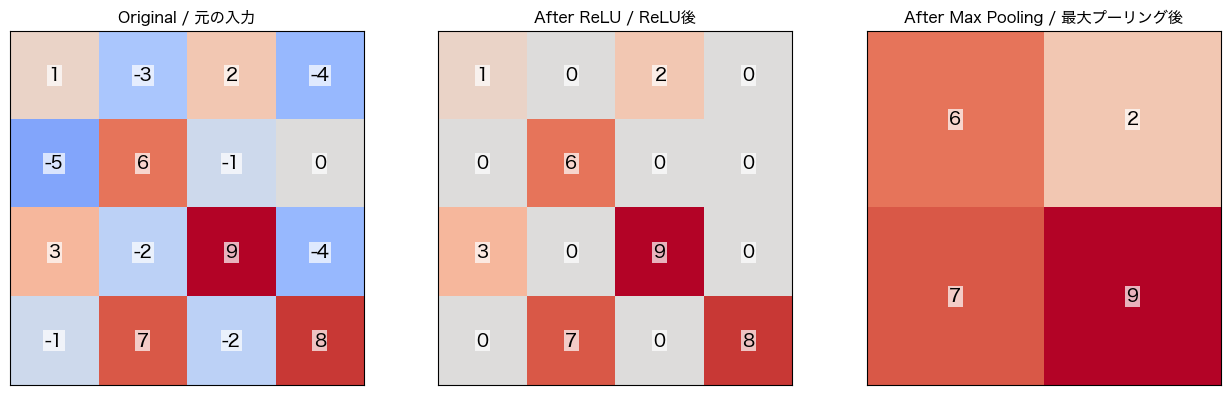

In [20]:
# 1. Create an example feature map
# EN: Use positive and negative values to demonstrate ReLU.
# JP: ReLUの動作を確認するため、正と負の値を用意します。
# ============================================================

toy = torch.tensor([[
    [
        [ 1., -3.,  2., -4.],
        [-5.,  6., -1.,  0.],
        [ 3., -2.,  9., -4.],
        [-1.,  7., -2.,  8.]
    ]
]])

# Shape: (batch, channels, height, width)
print("Input shape / 入力サイズ:", toy.shape)

# ============================================================
# 2. Apply ReLU
# EN: Replace all negative values with zero.
# JP: 負の値をすべて0に置き換えます。
# ============================================================

relu = nn.ReLU()
activated = relu(toy)

# ============================================================
# 3. Apply Max Pooling
# EN: Find the maximum in each 2x2 region.
# JP: 各2x2領域の最大値を取り出します。
# ============================================================

pool = nn.MaxPool2d(kernel_size=2, stride=2)
pooled = pool(activated)

# ============================================================
# 4. Print results
# ============================================================

print("\nOriginal / 元の入力:\n", toy[0, 0].numpy())
print("\nAfter ReLU / ReLU後:\n", activated[0, 0].numpy())
print("\nAfter Max Pooling / 最大プーリング後:\n",
      pooled[0, 0].numpy())

# ============================================================
# 5. Visualize the three stages
# EN: Compare original, ReLU output, and pooling output.
# JP: 元の入力、ReLU後、プーリング後を比較します。
# ============================================================

stages = [
    ("Original / 元の入力", toy[0, 0]),
    ("After ReLU / ReLU後", activated[0, 0]),
    ("After Max Pooling / 最大プーリング後", pooled[0, 0])
]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, (title, tensor) in zip(axes, stages):

    matrix = tensor.numpy()

    ax.imshow(matrix, cmap="coolwarm", vmin=-9, vmax=9)
    ax.set_title(title, fontsize=11)

    # EN: Show numerical values inside each cell.
    # JP: 各セルの数値を表示します。
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            ax.text(
                j, i, f"{matrix[i, j]:.0f}",
                ha="center", va="center",
                fontsize=13, color="black",
                bbox=dict(facecolor="white", alpha=0.7,
                          edgecolor="none", pad=1)
            )

    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.show()

## 4. Build the CNN / CNNモデルの構築
**EN:** `Conv2d(1,16,3,padding=1)` learns 16 different 3×3 filters from one grayscale channel. Padding 1 keeps height/width unchanged. `MaxPool2d(2)` halves them. The second convolution extracts combinations of earlier patterns. `Flatten` converts the feature maps into one vector. `Linear` produces **10 raw class scores (logits)**, one per digit; do not apply softmax before `CrossEntropyLoss`.

**日本語:** `Conv2d(1,16,3,padding=1)` は1チャネル画像から16種類の3×3フィルタを学習します。パディング1により縦横のサイズを維持します。`MaxPool2d(2)` は縦横を半分にします。2層目の畳み込みでは先に得られた特徴を組み合わせます。`Flatten` は特徴マップを1次元に変換し、`Linear` は**10クラス分のスコア（logits）**を出力します。`CrossEntropyLoss` の前にsoftmaxを付ける必要はありません。

**Shape path / サイズ変化:** `1×28×28 → 16×28×28 → 16×14×14 → 32×14×14 → 32×7×7 → 1568 → 64 → 10`.

In [21]:
class MNISTCNN(nn.Module):
    def __init__(self, filters=16):
        super().__init__()
        self.conv1=nn.Conv2d(1,filters,kernel_size=3,padding=1)
        self.relu1=nn.ReLU()
        self.pool1=nn.MaxPool2d(2)
        self.conv2=nn.Conv2d(filters,filters*2,kernel_size=3,padding=1)
        self.relu2=nn.ReLU()
        self.pool2=nn.MaxPool2d(2)
        self.classifier=nn.Sequential(nn.Flatten(),nn.Linear(filters*2*7*7,64),nn.ReLU(),nn.Linear(64,10))
    def forward(self,x):
        x=self.pool1(self.relu1(self.conv1(x)))
        x=self.pool2(self.relu2(self.conv2(x)))
        return self.classifier(x)

FILTERS=16  # experiment: 8, 16, 32 / 実験：フィルタ数を変更
model=MNISTCNN(filters=FILTERS).to(DEVICE)
print(model)
print('Trainable parameters / 学習可能パラメータ数:',sum(p.numel() for p in model.parameters() if p.requires_grad))
with torch.no_grad():
    sample_logits=model(torch.randn(2,1,28,28,device=DEVICE))
print('Output for two images / 2枚の画像に対する出力形状:',tuple(sample_logits.shape))

MNISTCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1568, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)
Trainable parameters / 学習可能パラメータ数: 105866
Output for two images / 2枚の画像に対する出力形状: (2, 10)


## 5. Train and validate / 学習と検証
**EN:** A **batch** is a group of examples processed together. In each training batch, the model predicts logits, `CrossEntropyLoss` measures error, backpropagation computes gradients, and **Adam** updates model weights. One **epoch** means seeing the full training dataset once. Validation calculates metrics without updating weights. We restore the checkpoint with lowest validation loss.

**日本語:** **バッチ**はまとめて処理する画像の集まりです。学習時にはモデルがスコアを予測し、`CrossEntropyLoss` で誤差を求め、誤差逆伝播で勾配を計算し、**Adam** で重みを更新します。**エポック**は学習データ全体を1回使うことです。検証時には重みを更新しません。最後に検証損失が最も小さいときの重みを復元します。

**Accuracy / 正解率:** `number of correct predictions ÷ number of samples`. / `正解数 ÷ サンプル数`。

**Note / 注意:** `EPOCHS` can be reduced to 2 to fit the lesson. / 授業時間が短い場合は2に減らせます。

In [22]:
# Shared training helpers / 学習・評価用関数
def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    sum_loss = correct = total = 0
    for images, labels in loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        if training: optimizer.zero_grad()
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, labels)
            if training:
                loss.backward()
                optimizer.step()
        batch_size = images.size(0)
        sum_loss += loss.item() * batch_size
        correct += (logits.argmax(1) == labels).sum().item()
        total += batch_size
    return sum_loss/total, correct/total

def train_model(model, train_loader, val_loader, epochs=3, lr=0.001):
    criterion = nn.CrossEntropyLoss()  # logits + integer labels (no softmax here)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss':[], 'train_acc':[], 'val_loss':[], 'val_acc':[]}
    best_val = float('inf'); best_state = None
    for epoch in range(1, epochs+1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer)
        with torch.no_grad():
            va_loss, va_acc = run_epoch(model, val_loader, criterion)
        for k,v in zip(history, [tr_loss,tr_acc,va_loss,va_acc]): history[k].append(v)
        if va_loss < best_val:
            best_val = va_loss
            best_state = copy.deepcopy(model.state_dict())
        print(f'Epoch {epoch:2d}/{epochs} | train loss {tr_loss:.3f}, acc {tr_acc:.1%} | '
              f'val loss {va_loss:.3f}, acc {va_acc:.1%} | {time.perf_counter()-t0:.1f}s')
    model.load_state_dict(best_state)  # choose checkpoint using validation only
    return history

def plot_history(history):
    fig, axes=plt.subplots(1,2,figsize=(11,3.6))
    axes[0].plot(history['train_loss'],marker='o',label='Train')
    axes[0].plot(history['val_loss'],marker='o',label='Validation')
    axes[0].set_title('Cross-entropy loss / 損失'); axes[0].set_ylabel('Loss')
    axes[1].plot(history['train_acc'],marker='o',label='Train')
    axes[1].plot(history['val_acc'],marker='o',label='Validation')
    axes[1].set_title('Accuracy / 正解率'); axes[1].set_ylabel('Accuracy')
    for ax in axes:
        ax.set_xlabel('Epoch index (starting at 0)');ax.legend();ax.grid(alpha=.2)
    plt.tight_layout();plt.show()

def get_predictions(model, loader):
    model.eval(); true=[]; pred=[]; prob=[]
    with torch.no_grad():
        for images,labels in loader:
            logits=model(images.to(DEVICE))
            probability=torch.softmax(logits,dim=1).cpu()
            true.extend(labels.tolist());pred.extend(probability.argmax(dim=1).tolist())
            prob.append(probability)
    return np.array(true),np.array(pred),torch.cat(prob).numpy()

Epoch  1/10 | train loss 0.375, acc 89.0% | val loss 0.131, acc 96.1% | 7.9s
Epoch  2/10 | train loss 0.094, acc 97.2% | val loss 0.080, acc 97.6% | 8.2s
Epoch  3/10 | train loss 0.063, acc 98.1% | val loss 0.061, acc 98.4% | 8.1s
Epoch  4/10 | train loss 0.050, acc 98.5% | val loss 0.052, acc 98.4% | 8.2s
Epoch  5/10 | train loss 0.040, acc 98.8% | val loss 0.052, acc 98.5% | 8.5s
Epoch  6/10 | train loss 0.034, acc 98.9% | val loss 0.043, acc 98.9% | 8.8s
Epoch  7/10 | train loss 0.027, acc 99.2% | val loss 0.045, acc 98.8% | 7.6s
Epoch  8/10 | train loss 0.024, acc 99.3% | val loss 0.043, acc 98.9% | 7.8s
Epoch  9/10 | train loss 0.020, acc 99.4% | val loss 0.051, acc 98.7% | 7.7s
Epoch 10/10 | train loss 0.018, acc 99.4% | val loss 0.050, acc 98.6% | 7.8s


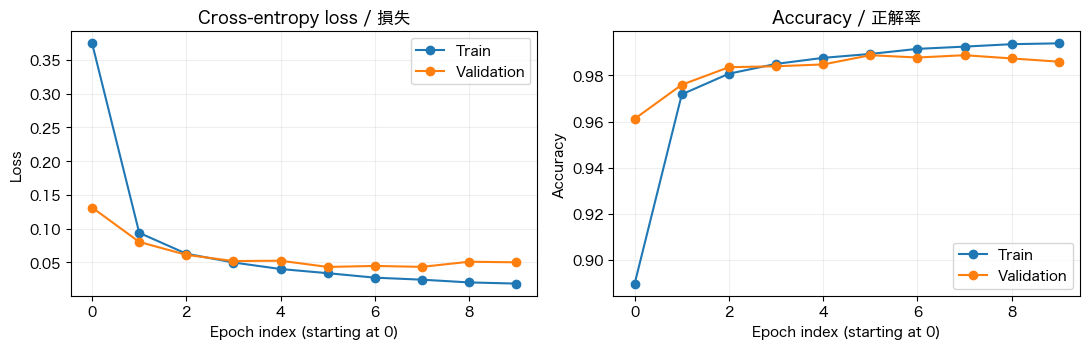

In [23]:
EPOCHS=10
history=train_model(model,train_loader,val_loader,epochs=EPOCHS,lr=0.001)
plot_history(history)

### Reading the learning curves / 学習曲線の見方
**EN:** A falling loss suggests the model is improving; rising validation loss while training loss continues to fall can indicate overfitting. Accuracy is easy to interpret, but loss also reflects prediction confidence.

**日本語:** 損失の減少は学習が進んでいることを示します。学習損失だけが下がり検証損失が上がる場合は、過学習の可能性があります。正解率は直感的ですが、損失は予測の確信度も反映します。

## 6. Evaluate on the untouched test set / 未使用のテストデータで評価
**EN:** Test accuracy estimates performance on held-out images. A **confusion matrix** shows which digits are confused (rows: true labels; columns: predictions). Inspecting failures is often more insightful than looking at accuracy alone.

**日本語:** テスト正解率は未使用画像に対する性能の目安です。**混同行列**はどの数字を取り違えたかを示します（行：正解、列：予測）。正解率だけでなく間違いを見ることで、モデルの弱点が分かります。

Test accuracy / テスト正解率: 98.79%


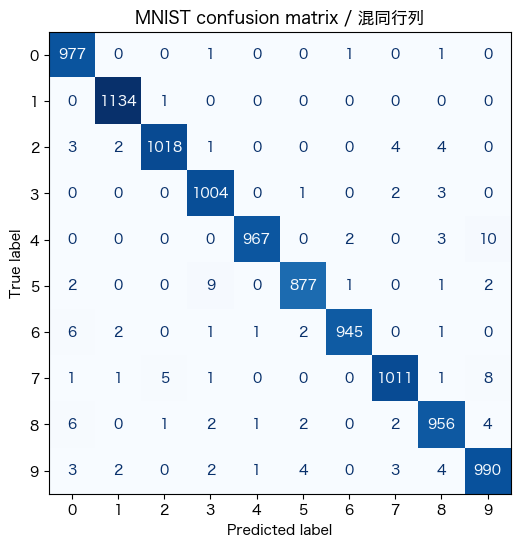

              precision    recall  f1-score   support

           0      0.979     0.997     0.988       980
           1      0.994     0.999     0.996      1135
           2      0.993     0.986     0.990      1032
           3      0.983     0.994     0.989      1010
           4      0.997     0.985     0.991       982
           5      0.990     0.983     0.987       892
           6      0.996     0.986     0.991       958
           7      0.989     0.983     0.986      1028
           8      0.982     0.982     0.982       974
           9      0.976     0.981     0.979      1009

    accuracy                          0.988     10000
   macro avg      0.988     0.988     0.988     10000
weighted avg      0.988     0.988     0.988     10000



In [24]:
truth,pred,probs=get_predictions(model,test_loader)
print(f'Test accuracy / テスト正解率: {(truth==pred).mean():.2%}')
cm=confusion_matrix(truth,pred,labels=list(range(10)))
fig,ax=plt.subplots(figsize=(7,6));ConfusionMatrixDisplay(cm,display_labels=list(range(10))).plot(ax=ax,cmap='Blues',colorbar=False)
ax.set_title('MNIST confusion matrix / 混同行列');plt.show()
print(classification_report(truth,pred,digits=3,zero_division=0))

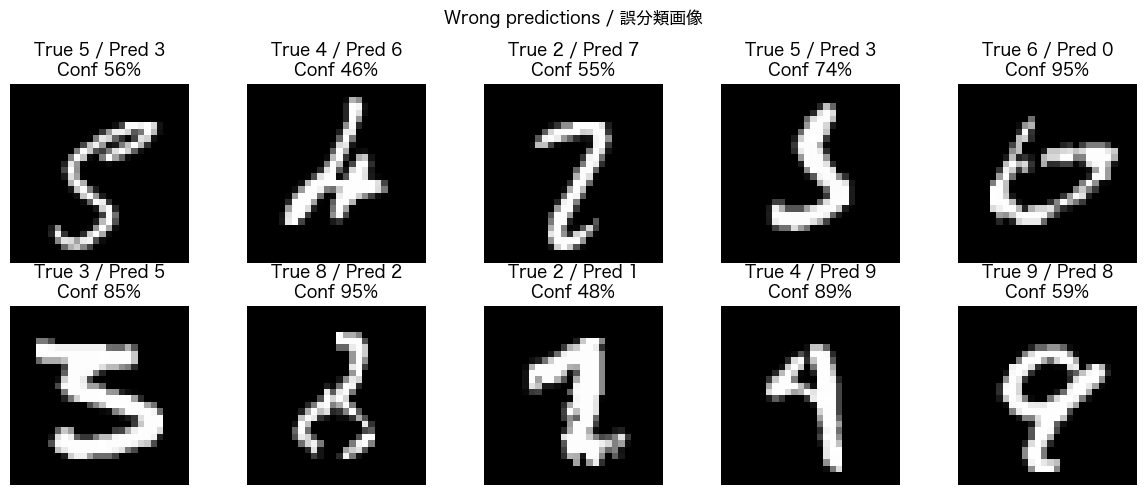

In [25]:
mistakes=np.flatnonzero(truth!=pred)
fig,axs=plt.subplots(2,5,figsize=(12,5))
for ax,idx in zip(axs.flat,mistakes[:10]):
    img,_=test_data[int(idx)]
    ax.imshow(img.squeeze(),cmap='gray'); ax.set_title(f'True {truth[idx]} / Pred {pred[idx]}\nConf {probs[idx,pred[idx]]:.0%}')
    ax.axis('off')
for ax in list(axs.flat)[min(10,len(mistakes)):]:ax.axis('off')
plt.suptitle('Wrong predictions / 誤分類画像');plt.tight_layout();plt.show()

## 7. Visualize learned filters and feature maps / 学習済みフィルタと特徴マップ
**EN:** Unlike the manually chosen edge kernel earlier, CNN filters are **learned** during training. Each first-layer feature map highlights where one learned filter responds. Later feature maps are more abstract and cannot necessarily be interpreted as a single edge or shape. Their numeric scales differ, so default plot colors are not directly comparable across channels.

**日本語:** 最初に手作業で決めたエッジ検出カーネルとは異なり、CNNのフィルタは**学習によって獲得**されます。1層目の特徴マップには各フィルタの応答位置が表れます。後段の特徴はより抽象的で、必ずしも単純なエッジや形状に対応しません。また、チャネルごとに値の範囲が異なるため、画像の色をそのまま比較しないでください。

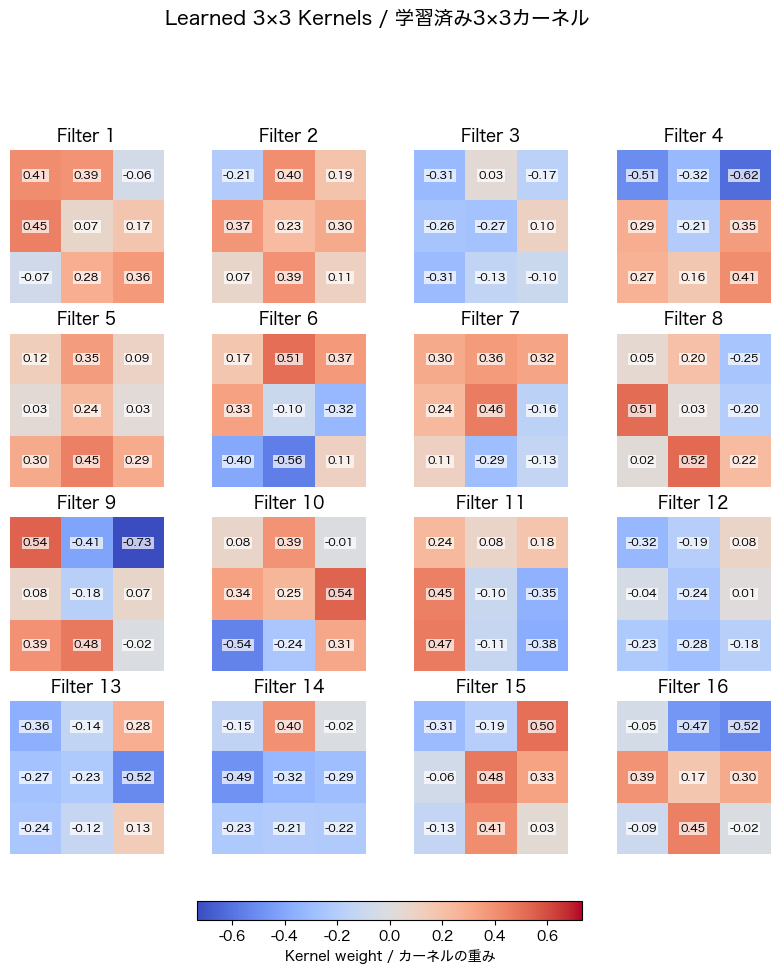

In [28]:
# Extract learned convolution kernels
# 学習済みの畳み込みカーネルを取得
w = model.conv1.weight.detach().cpu()[:, 0]  # [filters, 3, 3]

cols = 4
rows = int(np.ceil(len(w) / cols))

fig, axs = plt.subplots(rows, cols, figsize=(10, 2.5 * rows))

# Same color scale for all filters
# すべてのフィルタで同じカラースケールを使用
max_val = w.abs().max().item()

for i, ax in enumerate(np.array(axs).flat):
    if i < len(w):
        im = ax.imshow(
            w[i].numpy(),
            cmap="coolwarm",
            vmin=-max_val,
            vmax=max_val
        )

        ax.set_title(f"Filter {i + 1}")

        # Display numerical weight values
        # 各セルに重みの数値を表示
        for y in range(3):
            for x in range(3):
                value = w[i, y, x].item()
                ax.text(
                    x, y, f"{value:.2f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="black",
                    bbox=dict(
                        facecolor="white",
                        alpha=0.7,
                        edgecolor="none",
                        pad=1
                    )
                )

    ax.axis("off")

# Add a shared colorbar
# 全フィルタ共通のカラーバー
fig.colorbar(
    im,
    ax=np.array(axs).ravel().tolist(),
    orientation="horizontal",
    fraction=0.025,
    pad=0.06,
    label="Kernel weight / カーネルの重み"
)

fig.suptitle(
    "Learned 3×3 Kernels / 学習済み3×3カーネル",
    fontsize=14,
    y=1.02
)

plt.show()


In [15]:
# Intermediate activations / 中間特徴マップ
# Hooks capture layer outputs during the forward pass.
# hook は順伝播中に指定した層の出力を保存します。
def show_feature_maps(model, image_tensor, layer, title, max_channels=12):
    cache = {}
    def save_output(module, inputs, output):
        cache['activation'] = output.detach().cpu()
    handle = layer.register_forward_hook(save_output)
    model.eval()
    with torch.no_grad(): model(image_tensor.unsqueeze(0).to(DEVICE))
    handle.remove()  # important: avoid accumulating hooks / hook の重複を防ぐ
    maps=cache['activation'][0]
    count=min(max_channels,maps.shape[0]); cols=4;rows=int(np.ceil(count/cols))
    fig,axs=plt.subplots(rows,cols,figsize=(cols*2.6,rows*2.5))
    for i,ax in enumerate(np.array(axs).reshape(-1)):
        if i<count:
            ax.imshow(maps[i],cmap='viridis'); ax.set_title(f'Channel {i}')
        ax.axis('off')
    fig.suptitle(f'{title} | shape={tuple(maps.shape)}',y=1.02)
    plt.tight_layout();plt.show()
    return maps

True label / 正解: 7


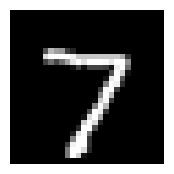

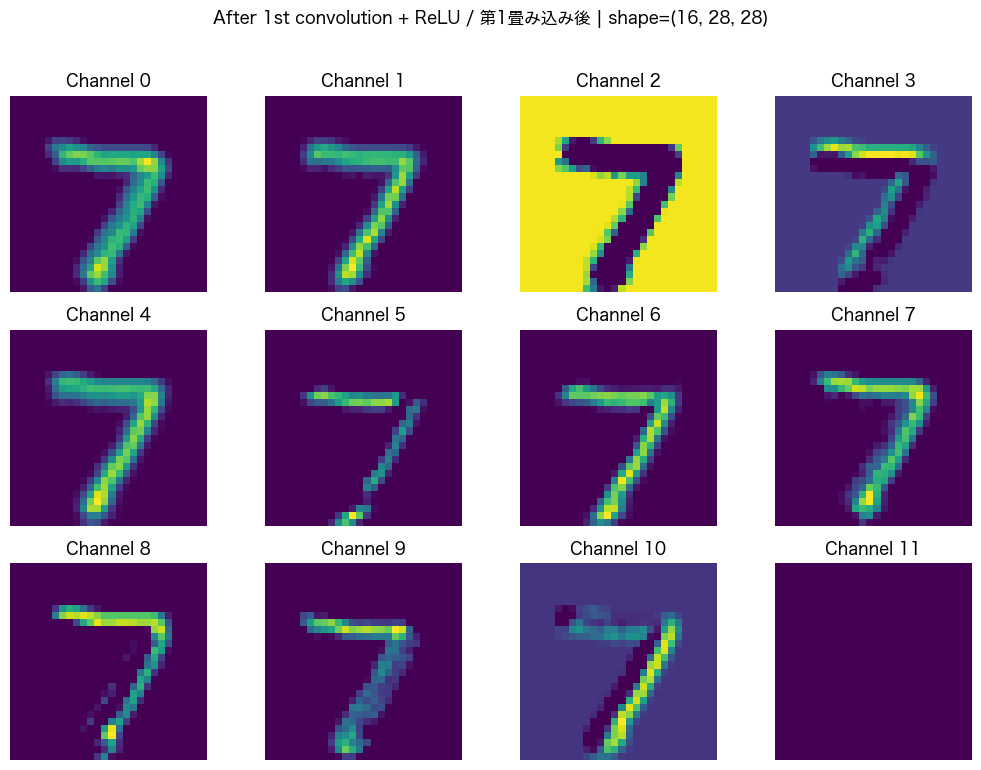

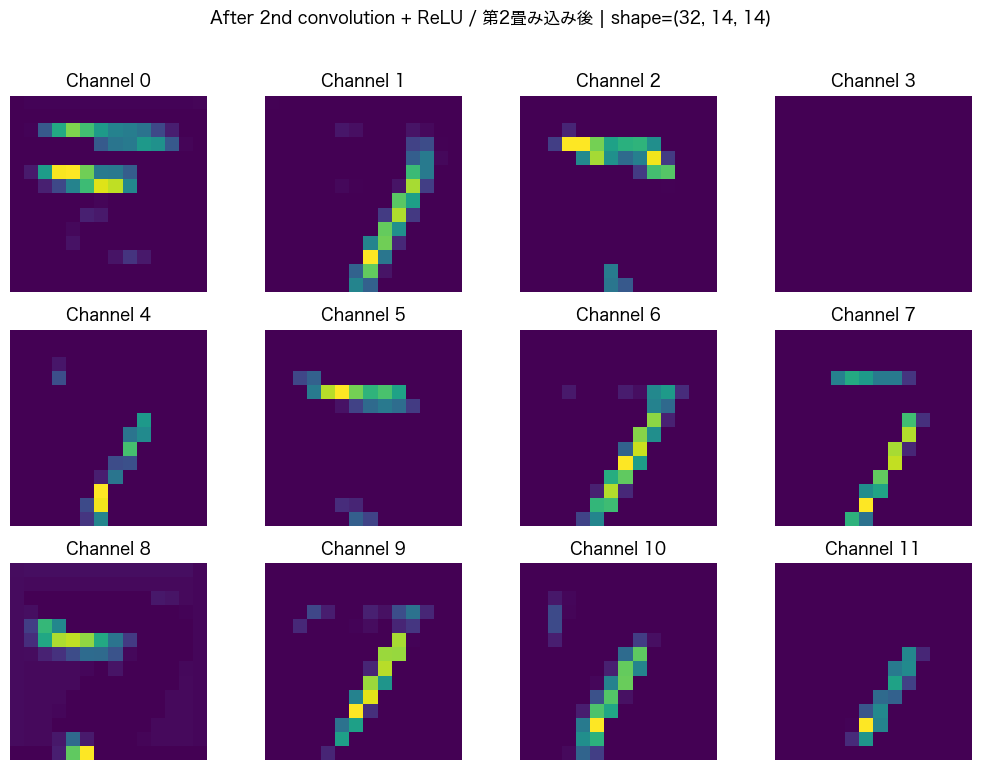

In [27]:
example_img,example_label=test_data[0]
print('True label / 正解:',example_label)
plt.figure(figsize=(2,2));plt.imshow(example_img.squeeze(),cmap='gray');plt.axis('off');plt.show()
map1=show_feature_maps(model,example_img,model.relu1,'After 1st convolution + ReLU / 第1畳み込み後')
map2=show_feature_maps(model,example_img,model.relu2,'After 2nd convolution + ReLU / 第2畳み込み後')

## 8. Inspect class probabilities / 各クラスの予測確率
**EN:** Softmax converts the 10 logits to nonnegative values summing to one. These are model confidence scores, not a guarantee that its probability estimates are calibrated.

**日本語:** Softmaxは10個のlogitを、合計が1となる非負の値に変換します。ただし、この値はモデルの確信度であり、現実の正答確率として完全に校正されているとは限りません。

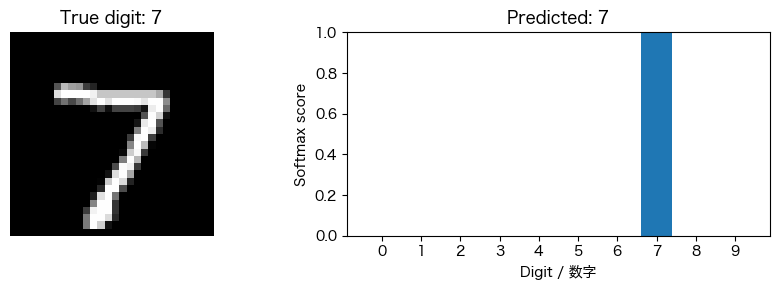

In [26]:
model.eval()
with torch.no_grad():
    p=torch.softmax(model(example_img.unsqueeze(0).to(DEVICE)),dim=1)[0].cpu().numpy()
fig,axs=plt.subplots(1,2,figsize=(9,3))
axs[0].imshow(example_img.squeeze(),cmap='gray');axs[0].axis('off');axs[0].set_title(f'True digit: {example_label}')
axs[1].bar(np.arange(10),p);axs[1].set_xticks(range(10));axs[1].set_ylim(0,1)
axs[1].set_xlabel('Digit / 数字');axs[1].set_ylabel('Softmax score');axs[1].set_title(f'Predicted: {p.argmax()}')
plt.tight_layout();plt.show()

## 9. Mini experiment / ミニ実験（10〜15分）
**EN:** Change **one parameter** (e.g., `FILTERS=8` or `FILTERS=32`) in Section 4, then rerun the model construction and training sections. Keep the same data split, epochs, and learning rate. Compare trainable parameter count, validation accuracy, and runtime. Do not choose parameters using the test set.

**日本語:** 4節のパラメータを**1つだけ**変えてください（例：`FILTERS=8` または `32`）。その後モデル構築と学習を再実行します。分割・エポック数・学習率は固定し、パラメータ数・検証正解率・処理時間を比較してください。テストデータを見て設定を決めないでください。

| Experiment / 条件 | Filters / フィルタ数 | Validation accuracy / 検証正解率 | Parameters / パラメータ数 |
|---|---:|---:|---:|
| A | 8 | *(fill in / 記入)* | *(fill in)* |
| B | 16 | *(fill in)* | *(fill in)* |
| C | 32 | *(fill in)* | *(fill in)* |

**Discussion / 考察:** Why can more filters help? What is the cost? / フィルタ数を増やす利点と欠点は何でしょうか？